# Deep Learning PR 1 — Breast Cancer Classification with SLP, MLP and Regularization
**Red & White Skill Education · Deep Learning · PR 1**

**Goal:** classify breast tumours as *Malignant* or *Benign* using the Breast Cancer Wisconsin (Diagnostic) dataset.
I begin with a single neuron (SLP) and then add one idea at a time: hidden layers, different activations, Early Stopping, Dropout and L1/L2 regularization, checking after each step what actually changed.

**Things to know before reading**
- In this dataset `0 = Malignant` and `1 = Benign`.
- Precision / recall / F1 in the final table are computed for the **Malignant** class (`pos_label=0`), because a missed cancer is the expensive mistake.
- Every model is seeded (`set_random_seed(42)`, deterministic ops), but numbers quoted in the *Observation* cells come from my run and may shift slightly on another machine or TensorFlow version.
- The test set has only 114 samples (one sample ≈ 0.88 %), and the validation split only 46, so small differences between models are within noise. I say so wherever it matters.
- To keep the notebook readable, long trainings use `verbose=0` and I print a short summary instead; the SLP and the first Early Stopping run use `verbose=1`.

## Task 1: Data Loading, EDA & Preprocessing
**Objective:** load the data, explore it, make a stratified train/test split and scale the features.

**Expected output:** shape and class counts, class distribution plot, correlation heatmap, scaled train/test arrays.

### 1.1 - Load the dataset

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # hide TensorFlow info messages

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import regularizers
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score)

sns.set_style("whitegrid")
os.makedirs("plots", exist_ok=True)      # every figure is saved here
RED, CHARCOAL = "#CC0000", "#2C2C2C"
CLASS_NAMES = ["Malignant (0)", "Benign (1)"]
SEED = 42

def reset_seed():
    """Same seed before every model, so each one starts from comparable conditions."""
    tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

I0000 00:00:1793265385.903189   27253 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793265387.034326   27253 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target

print("X.shape:", X.shape)
print("\nClass counts (0 = Malignant, 1 = Benign):")
print(y.value_counts())
print("\nMissing values in X:", int(X.isnull().sum().sum()))

X.shape: (569, 30)

Class counts (0 = Malignant, 1 = Benign):
target
1    357
0    212
Name: count, dtype: int64

Missing values in X: 0


In [3]:
X.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


### 1.2 - Class distribution plot

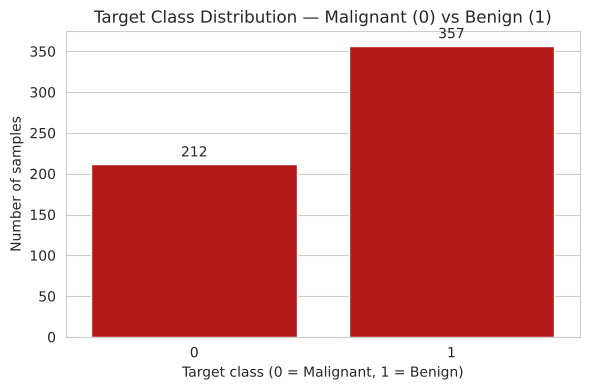

In [4]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x=y, color=RED)
ax.set_title("Target Class Distribution — Malignant (0) vs Benign (1)")
ax.set_xlabel("Target class (0 = Malignant, 1 = Benign)")
ax.set_ylabel("Number of samples")
for c in ax.containers:
    ax.bar_label(c, fmt="%d", padding=3)
plt.tight_layout()
plt.savefig("plots/01_class_distribution.png", dpi=120)
plt.show()

**Observation: class imbalance**


The data has 212 malignant (37 %) and 357 benign (63 %) samples, a mild imbalance (about 1 : 1.7), not a severe one. At this size I do not think oversampling, undersampling or class weights are needed, so I only use a stratified split to keep the ratio equal in both sets. Because accuracy can hide errors on the smaller class, I also report recall for the Malignant class separately from Task 2 onwards.

### 1.3 - Feature correlation heatmap

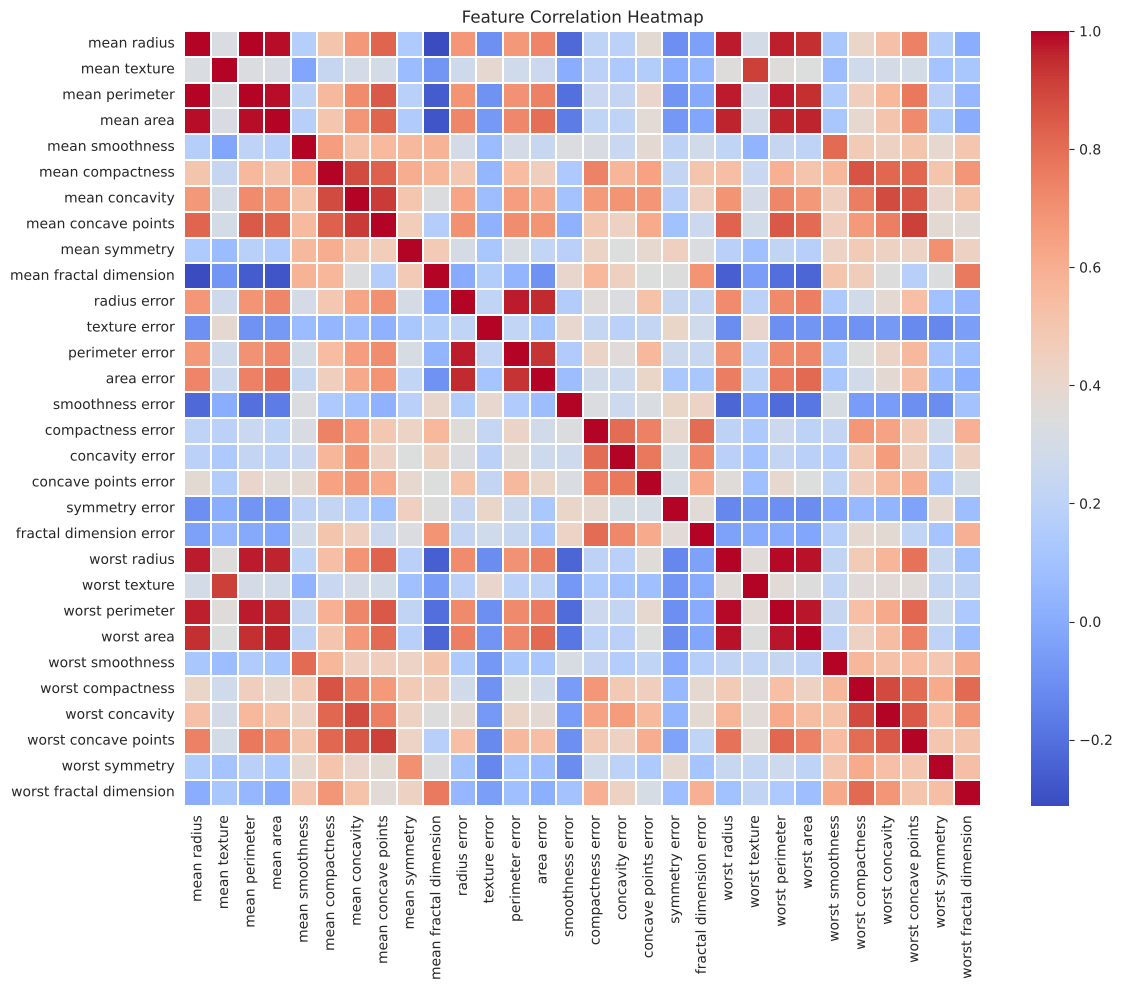

In [5]:
corr = X.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=False, cmap="coolwarm", linewidths=0.3)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig("plots/02_correlation_heatmap.png", dpi=120)
plt.show()

In [6]:
# the most correlated feature pairs (upper triangle only, so each pair appears once)
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
top_pairs = upper.stack().sort_values(ascending=False).head(5)
print(top_pairs.round(3))

mean radius     mean perimeter     0.998
worst radius    worst perimeter    0.994
mean radius     mean area          0.987
mean perimeter  mean area          0.987
worst radius    worst area         0.984
dtype: float64


**Observation: correlated features**


Many features are almost perfectly correlated. The strongest pairs (sklearn writes `mean radius`, the UCI file calls it `radius_mean`) are:
1. `mean radius` and `mean perimeter` (0.998)
2. `worst radius` and `worst perimeter` (0.994)
3. `mean radius` and `mean area` (0.987)

This is expected, because perimeter and area are computed from the radius of the nucleus.

**Is that a problem for a neural network?** Not in the way it is for linear models. In linear regression, correlated inputs cause multicollinearity: the coefficients become unstable and cannot be interpreted individually. A neural network is trained by gradient descent and we do not read single weights as effects, so correlated inputs just mean some redundancy that the network can share across many weights. (It can still make training slightly less efficient, which is one reason L2 regularization helps later.)

### 1.4 - Train / test split

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)
print("\nClass share in train:", y_train.value_counts(normalize=True).sort_index().round(3).to_dict())
print("Class share in test :", y_test.value_counts(normalize=True).sort_index().round(3).to_dict())

X_train: (455, 30) | X_test: (114, 30)
y_train: (455,) | y_test: (114,)

Class share in train: {0: 0.374, 1: 0.626}
Class share in test : {0: 0.368, 1: 0.632}


**Observation: stratified split**


Both sets keep the original class ratio (37.4 % / 62.6 % in train, 36.8 % / 63.2 % in test, against 37.3 % / 62.7 % overall), so `stratify=y` did its job. The training set has 455 rows and the test set 114.

### 1.5 - Apply StandardScaler

In [8]:
scaler = StandardScaler()
scaler.fit(X_train)                       # statistics come from the training data only

X_train_sc = scaler.transform(X_train)
X_test_sc = scaler.transform(X_test)

print("Train mean (first 10 features):", X_train_sc.mean(axis=0).round(2)[:10])
print("Train std  (first 10 features):", X_train_sc.std(axis=0).round(2)[:10])
print("All train means ~ 0:", np.allclose(X_train_sc.mean(axis=0), 0, atol=1e-6))
print("All train stds  ~ 1:", np.allclose(X_train_sc.std(axis=0), 1, atol=1e-6))
print("Test mean range    :", X_test_sc.mean(axis=0).min().round(2), "to", X_test_sc.mean(axis=0).max().round(2))

Train mean (first 10 features): [-0.  0. -0.  0.  0. -0. -0.  0. -0. -0.]
Train std  (first 10 features): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
All train means ~ 0: True
All train stds  ~ 1: True
Test mean range    : -0.13 to 0.13


**Why the scaler is fitted on the training set only**


The scaler is fitted on `X_train` only. If it also saw `X_test`, the test mean and standard deviation would leak into preprocessing (data leakage) and the test score would look better than it really is. The test set has to behave like new, unseen patients, so it is only *transformed* with the mean and std learned from the training data.

That is why the training features come out as exactly mean 0 / std 1, while the test features are only close to that (test means range from −0.13 to 0.13).

### 1.6 - WHY scaling matters for neural networks

Gradient-based optimisers (SGD, Adam) update every weight using a gradient that is proportional to the size of its input feature. When one feature lives in the thousands and another in the hundredths, the large one dominates the early updates and the small one barely moves the loss, so training is slow and biased towards the big-number features.

In this dataset `mean area` goes up to about 2500 while `mean fractal dimension` is only about 0.05–0.10. After `StandardScaler` every feature has mean 0 and standard deviation 1, so all of them start with a fair influence and the optimiser can use one learning rate that suits every weight, which makes convergence faster and more stable.

## Task 2: Single-Layer Perceptron (SLP) — Baseline Model
**Objective:** build the simplest possible neural network (one neuron) and use it as the baseline.

**Expected output:** summary with 31 parameters, training curves, test accuracy, classification report and confusion matrix.

### 2.1 - Build the SLP

In [9]:
reset_seed()
model_slp = keras.Sequential([
    keras.Input(shape=(30,)),
    keras.layers.Dense(1, activation="sigmoid")
])

A true SLP: one neuron, one weight per feature, one bias, no hidden layer.

### 2.2 - Compile the SLP

In [10]:
model_slp.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model_slp.summary()
assert model_slp.count_params() == 31

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │            31 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31 (124.00 B)

 Trainable params: 31 (124.00 B)

 Non-trainable params: 0 (0.00 B)

**Why binary cross-entropy?** The summary confirms 31 parameters (30 weights + 1 bias). The model outputs a probability *p* that the tumour is Benign, and binary cross-entropy is the negative log-likelihood of the true label under that probability: `-[y·log p + (1-y)·log(1-p)]`. It punishes a confident wrong answer very heavily. MSE is designed for continuous targets, and with a sigmoid output its gradient becomes tiny exactly when the model is confidently wrong, so learning would be slow.

### 2.3 - Train the SLP

In [11]:
history_slp = model_slp.fit(X_train_sc, y_train, epochs=50, batch_size=32,
                            validation_split=0.1, verbose=1)

Epoch 1/50


E0000 00:00:1793265388.657361   27253 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


 1/13 ━━━━━━━━━━━━━━━━━━━━ 7s 615ms/step - accuracy: 0.5312 - loss: 0.7971

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.4939 - loss: 0.8112 - val_accuracy: 0.3261 - val_loss: 0.8657


Epoch 2/50


 1/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.5938 - loss: 0.7108

... (143 outputs left out)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9682 - loss: 0.1450 - val_accuracy: 0.9565 - val_loss: 0.1782


Epoch 50/50


 1/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 1.0000 - loss: 0.1089

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9682 - loss: 0.1429 - val_accuracy: 0.9565 - val_loss: 0.1758


### 2.4 - Plot SLP training curves

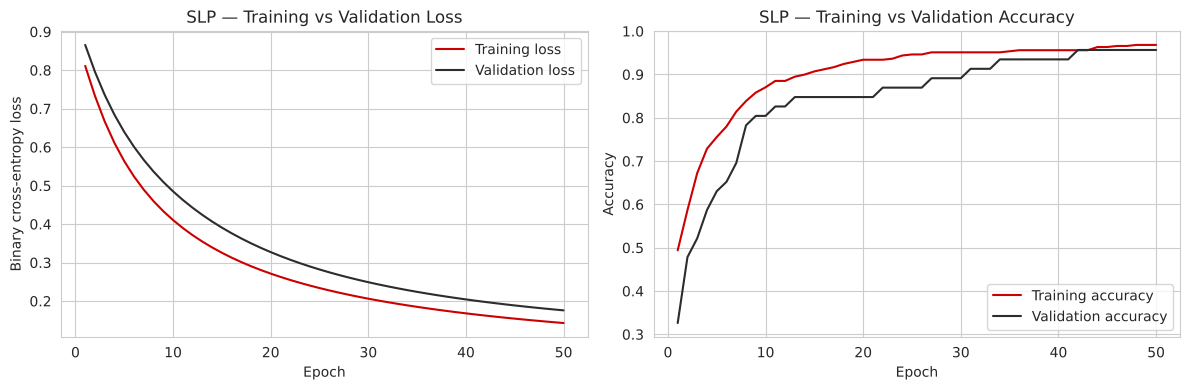

In [12]:
def plot_loss_acc(history, title, filename):
    h = history.history
    ep = range(1, len(h["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(ep, h["loss"], color=RED, label="Training loss")
    axes[0].plot(ep, h["val_loss"], color=CHARCOAL, label="Validation loss")
    axes[0].set(title=f"{title} — Training vs Validation Loss", xlabel="Epoch", ylabel="Binary cross-entropy loss")
    axes[1].plot(ep, h["accuracy"], color=RED, label="Training accuracy")
    axes[1].plot(ep, h["val_accuracy"], color=CHARCOAL, label="Validation accuracy")
    axes[1].set(title=f"{title} — Training vs Validation Accuracy", xlabel="Epoch", ylabel="Accuracy")
    for a in axes: a.legend()
    plt.tight_layout()
    plt.savefig(filename, dpi=120)
    plt.show()

plot_loss_acc(history_slp, "SLP", "plots/03_slp_training_curves.png")

**Observation: SLP learning curves**


The SLP converges smoothly: training loss falls from 0.81 (epoch 1) to 0.14 (epoch 50) with no jumps, and it is still decreasing at epoch 50, so it has not fully converged. Training accuracy ends at 96.8 % and validation accuracy at 95.7 %, and validation loss (0.176) sits a little above training loss (0.143). That small gap means no overfitting, which is expected for a model with only 31 parameters. Validation accuracy moves in visible steps because the validation split has only 46 samples.

### 2.5 - Evaluate the SLP

E0000 00:00:1793265394.952710   27253 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


SLP — test accuracy: 94.74 %  (test loss 0.1732)

               precision    recall  f1-score   support

Malignant (0)       0.95      0.90      0.93        42
   Benign (1)       0.95      0.97      0.96        72

     accuracy                           0.95       114
    macro avg       0.95      0.94      0.94       114
 weighted avg       0.95      0.95      0.95       114



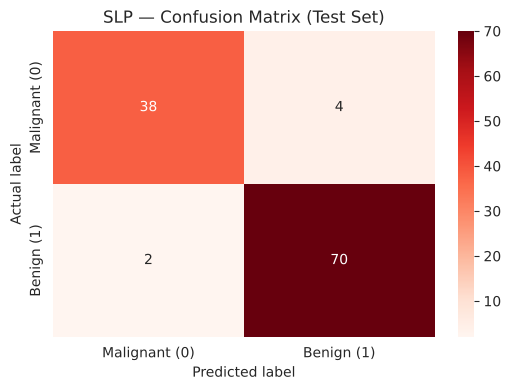

In [13]:
def evaluate_on_test(model, name, filename=None):
    """Test accuracy, classification report and confusion matrix for one model."""
    loss, acc = model.evaluate(X_test_sc, y_test, verbose=0)
    y_pred = (model.predict(X_test_sc, verbose=0) > 0.5).astype(int).ravel()
    print(f"{name} — test accuracy: {acc*100:.2f} %  (test loss {loss:.4f})\n")
    print(classification_report(y_test, y_pred, target_names=CLASS_NAMES))
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5.5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Reds", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(f"{name} — Confusion Matrix (Test Set)")
    plt.xlabel("Predicted label"); plt.ylabel("Actual label")
    plt.tight_layout()
    if filename: plt.savefig(filename, dpi=120)
    plt.show()
    return acc, y_pred

slp_acc, y_pred_slp = evaluate_on_test(model_slp, "SLP", "plots/04_slp_confusion_matrix.png")

**Observation: SLP test results**


Test accuracy is 94.74 %. For the Malignant class the recall is 0.90: the SLP missed 4 of 42 malignant tumours (called them Benign) and wrongly flagged 2 of 72 benign ones. This is a respectable baseline, but missing 4 cancers is exactly the error we most want to reduce.

In [14]:
# running record of test accuracies; the full table with all metrics is built in Task 7
results = pd.DataFrame({"Model": ["SLP"], "Test Accuracy (%)": [round(slp_acc * 100, 2)]})
results

,Model,Test Accuracy (%)
0,SLP,94.74


### 2.6 - SLP limitations

An SLP is one weighted sum passed through a sigmoid, so its decision boundary is a single flat hyperplane in the 30-dimensional feature space. It can only separate classes that are (nearly) linearly separable. There is no reason to expect tumour data to be perfectly separable by a flat surface, so the SLP is a realistic baseline that can still be improved. A network with hidden layers can bend the boundary, which is what Task 3 explores.

## Task 3: Multi-Layer Perceptron (MLP) — Activation Functions
**Objective:** add hidden layers and compare ReLU, Tanh and Sigmoid as hidden-layer activations.

**Expected output:** MLP summary with a verified parameter count, 3-panel activation comparison, best variant evaluated on the test set.

### 3.1 - Build the MLP (ReLU)

In [15]:
reset_seed()
model_mlp = keras.Sequential([
    keras.Input(shape=(30,)),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
])
model_mlp.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
l1_params = 30 * 64 + 64      # weights + biases
l2_params = 64 * 32 + 32
out_params = 32 * 1 + 1
print(f"Hidden 1: 30x64 + 64 = {l1_params}")
print(f"Hidden 2: 64x32 + 32 = {l2_params}")
print(f"Output  : 32x1  + 1  = {out_params}")
print("Manual total :", l1_params + l2_params + out_params)
print("Summary total:", model_mlp.count_params())
assert l1_params + l2_params + out_params == model_mlp.count_params()

Hidden 1: 30x64 + 64 = 1984
Hidden 2: 64x32 + 32 = 2080
Output  : 32x1  + 1  = 33
Manual total : 4097
Summary total: 4097


### 3.2 - WHY hidden layers

Every Dense layer computes a weighted sum and then applies a non-linear activation, so it produces a new, non-linear representation of its input. With two hidden layers, the second layer combines the features built by the first, giving a small hierarchy of feature interactions. By the Universal Approximation Theorem a single hidden layer can in theory approximate any continuous function, but it may need many neurons; in practice two moderately sized layers often train faster on tabular data like this. The SLP had none of this and could only draw one straight boundary.

### 3.3 - Compile and train the MLP (ReLU)

In [17]:
model_mlp.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
history_mlp = model_mlp.fit(X_train_sc, y_train, epochs=100, batch_size=32,
                            validation_split=0.1, verbose=0)
print("Trained 100 epochs | final train acc:", round(history_mlp.history["accuracy"][-1], 4),
      "| final val acc:", round(history_mlp.history["val_accuracy"][-1], 4))

Trained 100 epochs | final train acc: 1.0 | final val acc: 1.0


### 3.4 - Compare activation functions

In [18]:
def build_mlp(activation, hidden=(64, 32), dropout=0.0, reg=None):
    """MLP builder used for the variants; same layout as the explicit models above."""
    layers = [keras.Input(shape=(30,))]
    for units in hidden:
        layers.append(keras.layers.Dense(units, activation=activation, kernel_regularizer=reg))
        if dropout > 0:
            layers.append(keras.layers.Dropout(dropout))
    layers.append(keras.layers.Dense(1, activation="sigmoid"))
    m = keras.Sequential(layers)
    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return m

reset_seed()
model_tanh = build_mlp("tanh")
history_tanh = model_tanh.fit(X_train_sc, y_train, epochs=100, batch_size=32, validation_split=0.1, verbose=0)

reset_seed()
model_sigmoid = build_mlp("sigmoid")
history_sigmoid = model_sigmoid.fit(X_train_sc, y_train, epochs=100, batch_size=32, validation_split=0.1, verbose=0)

E0000 00:00:1793265406.626687   27253 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793265416.889677   27253 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


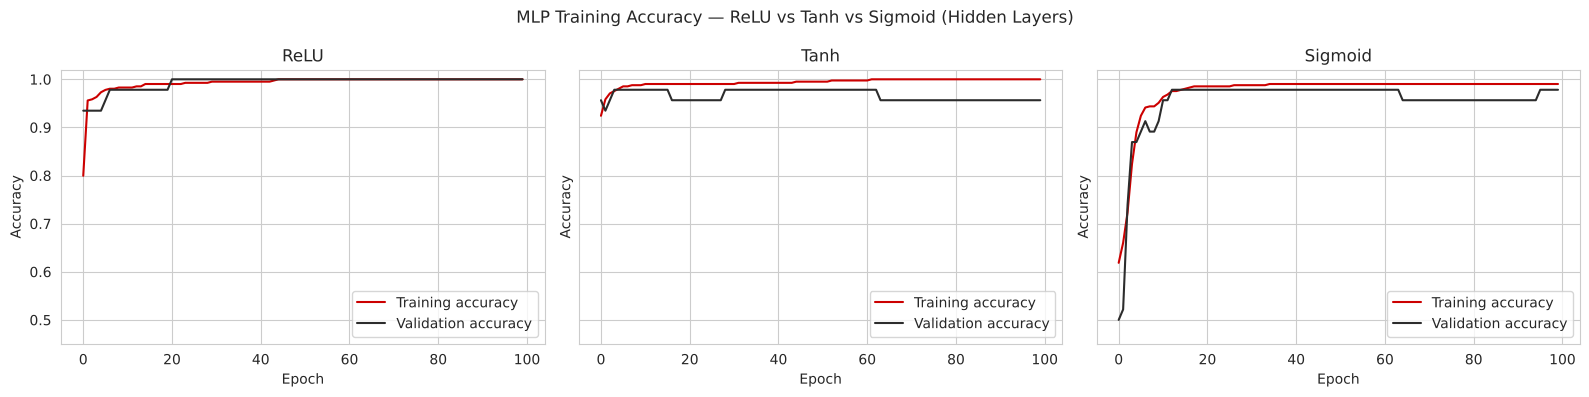

In [19]:
act_names = ["ReLU", "Tanh", "Sigmoid"]
act_hist = [history_mlp, history_tanh, history_sigmoid]

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, name, h in zip(axes, act_names, act_hist):
    ax.plot(h.history["accuracy"], color=RED, label="Training accuracy")
    ax.plot(h.history["val_accuracy"], color=CHARCOAL, label="Validation accuracy")
    ax.set(title=name, xlabel="Epoch", ylabel="Accuracy", ylim=(0.45, 1.02))
    ax.legend(loc="lower right")
fig.suptitle("MLP Training Accuracy — ReLU vs Tanh vs Sigmoid (Hidden Layers)")
plt.tight_layout()
plt.savefig("plots/05_activation_comparison.png", dpi=120)
plt.show()

In [20]:
act_table = pd.DataFrame({
    "Epoch-1 Train Acc": [h.history["accuracy"][0] for h in act_hist],
    "Final Train Acc": [h.history["accuracy"][-1] for h in act_hist],
    "Final Val Acc": [h.history["val_accuracy"][-1] for h in act_hist],
    "Final Val Loss": [h.history["val_loss"][-1] for h in act_hist],
    "Best Val Loss": [min(h.history["val_loss"]) for h in act_hist],
}, index=act_names).round(4)
act_table

,Epoch-1 Train Acc,Final Train Acc,Final Val Acc,Final Val Loss,Best Val Loss
ReLU,0.7995,1.0000,1.0000,0.0034,0.0034
Tanh,0.9242,1.0000,0.9565,0.1401,0.0580
Sigmoid,0.6186,0.9902,0.9783,0.0478,0.0478


### 3.5 - Activation functions compared

- **ReLU** — `max(0, x)`. Gradient is 1 for positive inputs, so no vanishing gradient there, and it is cheap to compute; it usually converges fastest on tabular data. Risk: "dying ReLU" — a neuron that always receives negative input has zero gradient and stops learning.
- **Tanh** — output in (−1, 1) and zero-centred, which is friendlier to the next layer than Sigmoid, but its gradient still shrinks for large |x|, so it can suffer from vanishing gradients in deep networks.
- **Sigmoid (hidden)** — output in (0, 1), not zero-centred, and its derivative is at most 0.25, so gradients shrink layer after layer in deep nets. It belongs in the output layer of a binary classifier, not in hidden layers.

**Which activation performed best here?**


**ReLU performed best here**: final validation accuracy 1.00 and by far the lowest final validation loss (0.0034, against 0.0478 for Sigmoid and 0.1401 for Tanh).

- **Tanh** learned fastest at the start (0.92 training accuracy after epoch 1, against 0.80 for ReLU and 0.62 for Sigmoid), but it ended with the highest validation loss and 0.9565 validation accuracy, so it overfitted the most. Its best validation loss (0.058) came earlier than its last epoch.
- **Sigmoid** started slowest (0.62 after epoch 1), which fits the theory about its small gradients, and it reached 0.99 training accuracy only by the end.

An honest caveat: with only two hidden layers vanishing gradients are not a big problem, so all three end up fairly close, and a 46-sample validation set makes the ranking a hint rather than proof. I picked ReLU.

### 3.6 - Evaluate the best MLP

Best activation: ReLU 



E0000 00:00:1793265427.822253   27253 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


MLP (ReLU) — test accuracy: 96.49 %  (test loss 0.1292)

               precision    recall  f1-score   support

Malignant (0)       0.93      0.98      0.95        42
   Benign (1)       0.99      0.96      0.97        72

     accuracy                           0.96       114
    macro avg       0.96      0.97      0.96       114
 weighted avg       0.97      0.96      0.97       114



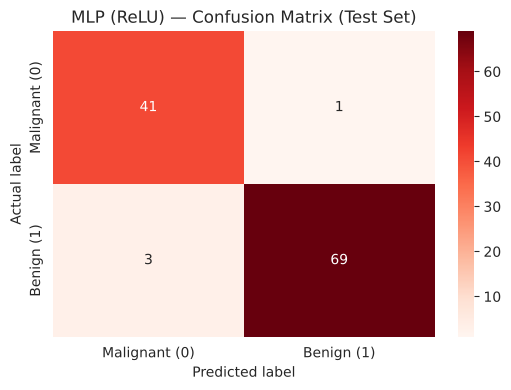

In [21]:
# best = highest final validation accuracy; lower final validation loss breaks ties
best_act = act_table.sort_values(["Final Val Acc", "Final Val Loss"], ascending=[False, True]).index[0]
best_mlp = {"ReLU": model_mlp, "Tanh": model_tanh, "Sigmoid": model_sigmoid}[best_act]
print("Best activation:", best_act, "\n")
mlp_acc, y_pred_mlp = evaluate_on_test(best_mlp, f"MLP ({best_act})", "plots/06_mlp_confusion_matrix.png")

In [22]:
results.loc[len(results)] = [f"MLP ({best_act})", round(mlp_acc * 100, 2)]
print(results.to_string(index=False))
print(f"\nMLP vs SLP: {(mlp_acc - slp_acc) * 100:+.2f} percentage points")

     Model  Test Accuracy (%)
       SLP              94.74
MLP (ReLU)              96.49

MLP vs SLP: +1.75 percentage points


**Observation: MLP vs SLP**


Test accuracy rose from 94.74 % (SLP) to 96.49 % (MLP-ReLU), +1.75 points (2 more samples correct). The more important change is the Malignant recall, which went from 0.90 to 0.98: missed malignant tumours fell from 4 to 1. The price is a small drop in Malignant precision (0.95 → 0.93), since 3 benign tumours were flagged instead of 2. So the hidden layers helped where the SLP was weakest, as the linear-boundary argument predicted.

## Task 4: Early Stopping
**Objective:** train a bigger MLP for many epochs and use Early Stopping to stop before it overfits.

**Expected output:** curves with the stopping epoch marked, and a comparison of the model with and without Early Stopping.

### 4.1 - Build the MLP for the Early Stopping experiment

In [23]:
def build_es_mlp():
    return keras.Sequential([
        keras.Input(shape=(30,)),
        keras.layers.Dense(128, activation="relu"),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dense(1, activation="sigmoid")
    ])

reset_seed()
model_es = build_es_mlp()
model_es.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model_es.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

### 4.2 - Add the EarlyStopping callback

In [24]:
es = EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True, verbose=1)

history_es = model_es.fit(X_train_sc, y_train, epochs=300, batch_size=32,
                          validation_split=0.1, callbacks=[es], verbose=1)

Epoch 1/300


 1/13 ━━━━━━━━━━━━━━━━━━━━ 9s 752ms/step - accuracy: 0.5625 - loss: 0.6889

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.8753 - loss: 0.4476 - val_accuracy: 0.8913 - val_loss: 0.3377


Epoch 2/300


 1/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9375 - loss: 0.2602

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9511 - loss: 0.1975 - val_accuracy: 0.9130 - val_loss: 0.2122


... (184 outputs left out)

 1/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 1.0000 - loss: 4.6758e-04

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 8.8707e-04 - val_accuracy: 1.0000 - val_loss: 0.0315


Epoch 64: early stopping


Restoring model weights from the end of the best epoch: 49.


### 4.3 - WHY Early Stopping — the four parameters

1. **`monitor="val_loss"`** — watch the validation loss, not the training loss. Training loss almost always keeps falling because the network can memorise the training set; only validation loss shows whether the model still generalises.
2. **`patience=15`** — allow 15 epochs in a row without improvement before stopping. Validation loss is noisy, so this avoids quitting at a small temporary bump.
3. **`restore_best_weights=True`** — after stopping, roll the weights back to the epoch with the lowest `val_loss`. Without it the model keeps the weights from the last epoch, which is `patience` epochs *past* the best one.
4. **`verbose=1`** — prints the epoch at which training stopped.

### 4.4 - Plot Early Stopping curves

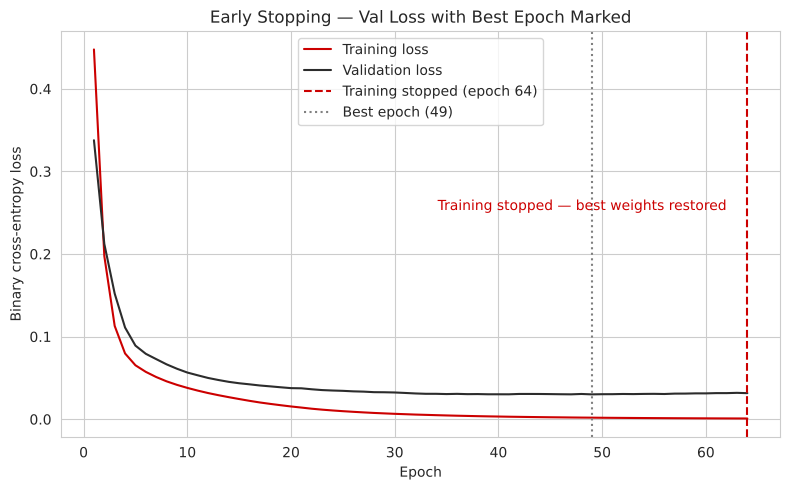

Stopped at epoch 64; best val_loss 0.0301 at epoch 49


In [25]:
stop_epoch = len(history_es.history["loss"])
best_epoch_es = int(np.argmin(history_es.history["val_loss"])) + 1
ep = range(1, stop_epoch + 1)

plt.figure(figsize=(8, 5))
plt.plot(ep, history_es.history["loss"], color=RED, label="Training loss")
plt.plot(ep, history_es.history["val_loss"], color=CHARCOAL, label="Validation loss")
plt.axvline(stop_epoch, color=RED, linestyle="--", label=f"Training stopped (epoch {stop_epoch})")
plt.axvline(best_epoch_es, color="grey", linestyle=":", label=f"Best epoch ({best_epoch_es})")
plt.annotate("Training stopped — best weights restored",
             xy=(stop_epoch, max(history_es.history["val_loss"]) * 0.6),
             xytext=(stop_epoch - 2, max(history_es.history["val_loss"]) * 0.75),
             ha="right", color=RED)
plt.title("Early Stopping — Val Loss with Best Epoch Marked")
plt.xlabel("Epoch"); plt.ylabel("Binary cross-entropy loss")
plt.legend()
plt.tight_layout()
plt.savefig("plots/07_early_stopping_curves.png", dpi=120)
plt.show()
print(f"Stopped at epoch {stop_epoch}; best val_loss {min(history_es.history['val_loss']):.4f} at epoch {best_epoch_es}")

**Observation: Early Stopping curve**


Training stopped at epoch 64. With `patience=15`, the best epoch was 15 epochs earlier, epoch 49 (val_loss 0.0301), and `restore_best_weights=True` put the weights from that epoch back (the callback printed this). In the plot, training loss keeps falling after epoch 49 while validation loss stops improving, which is where overfitting begins.

### 4.5 - Compare: with vs without Early Stopping

In [26]:
# identical architecture and seed, but no callback and the full 300 epochs
reset_seed()
model_no_es = build_es_mlp()
model_no_es.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
history_no_es = model_no_es.fit(X_train_sc, y_train, epochs=300, batch_size=32,
                                validation_split=0.1, verbose=0)
print("Trained all", len(history_no_es.history["loss"]), "epochs without a callback")

E0000 00:00:1793265436.026146   27253 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Trained all 300 epochs without a callback


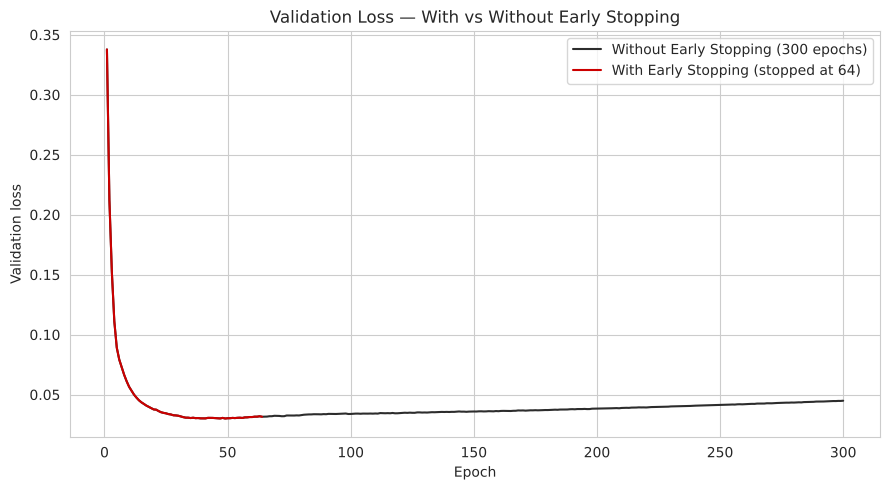

Without ES: lowest val_loss 0.0301 at epoch 49; val_loss at epoch 300 = 0.0449
With ES   : final (restored) val_loss 0.0301; training stopped at epoch 64


In [27]:
v_no = history_no_es.history["val_loss"]
v_es = history_es.history["val_loss"]

plt.figure(figsize=(9, 5))
plt.plot(range(1, len(v_no) + 1), v_no, color=CHARCOAL, label="Without Early Stopping (300 epochs)")
plt.plot(range(1, len(v_es) + 1), v_es, color=RED, label=f"With Early Stopping (stopped at {stop_epoch})")
plt.title("Validation Loss — With vs Without Early Stopping")
plt.xlabel("Epoch"); plt.ylabel("Validation loss")
plt.legend()
plt.tight_layout()
plt.savefig("plots/08_early_stopping_comparison.png", dpi=120)
plt.show()

best_no = int(np.argmin(v_no)) + 1
print(f"Without ES: lowest val_loss {min(v_no):.4f} at epoch {best_no}; val_loss at epoch 300 = {v_no[-1]:.4f}")
print(f"With ES   : final (restored) val_loss {min(v_es):.4f}; training stopped at epoch {stop_epoch}")

In [28]:
_, acc_no_es = model_no_es.evaluate(X_test_sc, y_test, verbose=0)
_, acc_es = model_es.evaluate(X_test_sc, y_test, verbose=0)
print(f"Test accuracy without Early Stopping: {acc_no_es*100:.2f} %")
print(f"Test accuracy with Early Stopping   : {acc_es*100:.2f} %")
results.loc[len(results)] = ["MLP + Early Stopping", round(acc_es * 100, 2)]

Test accuracy without Early Stopping: 97.37 %
Test accuracy with Early Stopping   : 96.49 %


E0000 00:00:1793265464.891913   27253 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


**Observation: with vs without Early Stopping**


Both models use the same seed and architecture, so their curves are identical until Early Stopping ends the first run. Without the callback, validation loss is lowest at epoch 49 (0.0301) and then drifts up, reaching 0.0449 at epoch 300, about 49 % worse than its best, so overfitting starts around epochs 49–50. The Early Stopping model keeps the best value (0.0301), so its validation loss is lower, and it needs 64 epochs instead of 300.

On the **test set**, however, the no-callback model scored 97.37 % and the Early Stopping model 96.49 %, a difference of 1 sample out of 114. So in this run Early Stopping improved validation loss but not test accuracy. An overfitted network gets over-confident (its loss rises) without necessarily flipping many yes/no predictions, and 1 sample is within noise.

## Task 5: Dropout Layers
**Objective:** add Dropout to reduce overfitting and find which rate works best.

**Expected output:** Dropout model summary, validation accuracy for rates 0.1 / 0.3 / 0.5, and the best one evaluated on the test set.

### 5.1 - Build MLP with Dropout

In [29]:
reset_seed()
model_drop = keras.Sequential([
    keras.Input(shape=(30,)),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(1, activation="sigmoid")
])
model_drop.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_16 (Dense)                │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

Dropout layers show 0 parameters: they learn nothing and only zero random activations while training.

### 5.2 - WHY Dropout

- **During training**, `Dropout(0.3)` sets a random 30 % of the layer's outputs to zero in every batch.
- **Redundant representations:** any neuron can vanish at any step, so the network cannot rely on a few neurons and must spread what it knows over many.
- **At inference** (`model.predict`) Dropout is switched off and all neurons are used. Keras uses *inverted* dropout — the kept activations are divided by the keep probability (0.7) during training — so outputs stay on the same scale and nothing needs rescaling at test time.
- **Ensemble view:** each batch trains a different thinned sub-network (up to 2ⁿ of them for n neurons) and they all share weights; the full network at inference behaves like an average of them, which lowers variance and improves generalisation.

### 5.3 - Train with Dropout + Early Stopping

In [30]:
model_drop.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
es_drop = EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True, verbose=1)
history_drop = model_drop.fit(X_train_sc, y_train, epochs=300, batch_size=32,
                              validation_split=0.1, callbacks=[es_drop], verbose=0)
print("Dropout 0.3 trained for", len(history_drop.history["loss"]), "epochs")

Epoch 122: early stopping


Restoring model weights from the end of the best epoch: 102.


Dropout 0.3 trained for 122 epochs


### 5.4 - Effect of the Dropout rate

In [31]:
drop_models = {0.3: model_drop}
drop_hist = {0.3: history_drop}

for rate in (0.1, 0.5):
    reset_seed()
    m = build_mlp("relu", hidden=(128, 64), dropout=rate)
    stopper = EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True, verbose=1)
    print(f"--- dropout {rate}")
    drop_hist[rate] = m.fit(X_train_sc, y_train, epochs=200, batch_size=32,
                            validation_split=0.1, callbacks=[stopper], verbose=0)
    drop_models[rate] = m

--- dropout 0.1


E0000 00:00:1793265478.247880   27253 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Epoch 84: early stopping


Restoring model weights from the end of the best epoch: 64.


--- dropout 0.5


E0000 00:00:1793265487.611382   27253 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Epoch 118: early stopping


Restoring model weights from the end of the best epoch: 98.


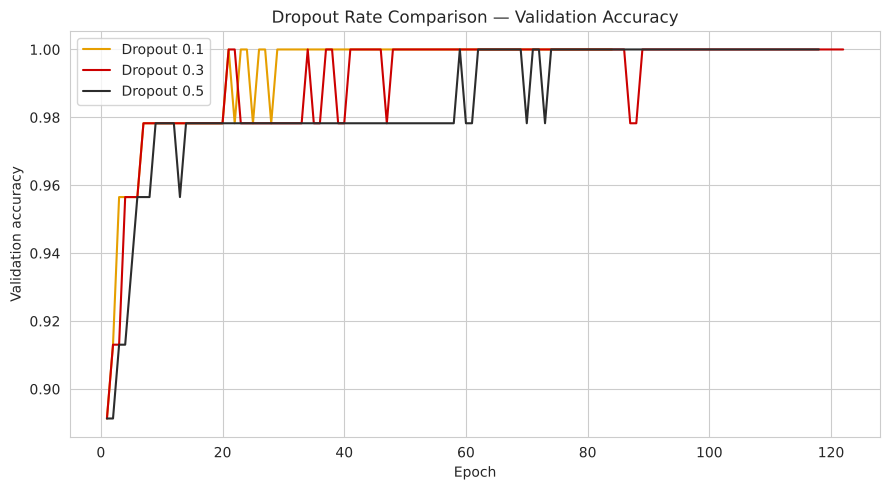

In [32]:
plt.figure(figsize=(9, 5))
for rate, col in zip((0.1, 0.3, 0.5), ("#E69F00", RED, CHARCOAL)):
    plt.plot(range(1, len(drop_hist[rate].history["val_accuracy"]) + 1),
             drop_hist[rate].history["val_accuracy"], color=col, label=f"Dropout {rate}")
plt.title("Dropout Rate Comparison — Validation Accuracy")
plt.xlabel("Epoch"); plt.ylabel("Validation accuracy")
plt.legend()
plt.tight_layout()
plt.savefig("plots/09_dropout_rate_comparison.png", dpi=120)
plt.show()

In [33]:
drop_table = pd.DataFrame({
    "Epochs Trained": [len(drop_hist[r].history["loss"]) for r in (0.1, 0.3, 0.5)],
    "Best Val Loss": [min(drop_hist[r].history["val_loss"]) for r in (0.1, 0.3, 0.5)],
    "Best Val Acc": [max(drop_hist[r].history["val_accuracy"]) for r in (0.1, 0.3, 0.5)],
}, index=pd.Index([0.1, 0.3, 0.5], name="Dropout Rate")).round(4)
drop_table

,Epochs Trained,Best Val Loss,Best Val Acc
Dropout Rate,,,
0.1,84,0.0131,1.0
0.3,122,0.0047,1.0
0.5,118,0.0036,1.0


**Observation: the dropout-rate trade-off**


- **Rate 0.1** gives the weakest regularization: it stopped earliest (84 epochs, best at 64) and has the highest validation loss (0.0131).
- **Rate 0.3** reached 0.0047 and **rate 0.5** 0.0036, and both trained longer (122 and 118 epochs), because stronger noise makes each step less effective and slows learning.
- All three hit a best validation accuracy of 1.0, so accuracy cannot separate them on 46 samples; validation loss can.

The expected downside of a high rate (underfitting) did not show up at 0.5 on this small, easy dataset. I picked 0.5 (lowest validation loss), but 0.3 and 0.5 are very close.

### 5.5 - Evaluate the Dropout model

Best dropout rate: 0.5 



MLP + Dropout (0.5) — test accuracy: 95.61 %  (test loss 0.1488)

               precision    recall  f1-score   support

Malignant (0)       0.91      0.98      0.94        42
   Benign (1)       0.99      0.94      0.96        72

     accuracy                           0.96       114
    macro avg       0.95      0.96      0.95       114
 weighted avg       0.96      0.96      0.96       114



E0000 00:00:1793265500.210596   27253 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


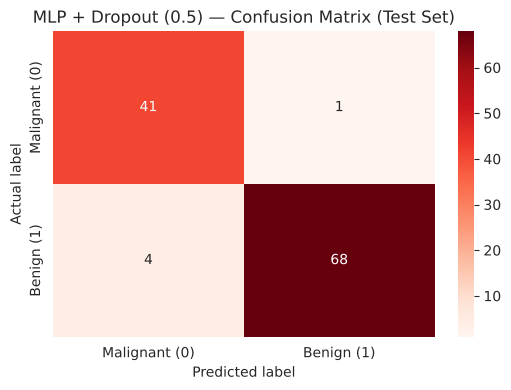

In [34]:
best_rate = drop_table["Best Val Loss"].idxmin()          # lowest validation loss
best_drop = drop_models[best_rate]
print("Best dropout rate:", best_rate, "\n")
drop_acc, y_pred_drop = evaluate_on_test(best_drop, f"MLP + Dropout ({best_rate})", "plots/10_dropout_confusion_matrix.png")
results.loc[len(results)] = [f"MLP + Dropout ({best_rate})", round(drop_acc * 100, 2)]

In [35]:
# train vs validation accuracy at each model's best epoch (lowest val_loss)
def gap_at_best(h):
    i = int(np.argmin(h.history["val_loss"]))
    return h.history["accuracy"][i], h.history["val_accuracy"][i]

for name, h in [("Without Dropout (Task 4)", history_es), (f"With Dropout {best_rate}", drop_hist[best_rate])]:
    tr, va = gap_at_best(h)
    print(f"{name:26s} train {tr:.4f} | val {va:.4f} | gap {tr - va:+.4f}")

Without Dropout (Task 4)   train 1.0000 | val 1.0000 | gap +0.0000
With Dropout 0.5           train 0.9951 | val 1.0000 | gap -0.0049


**Observation: Dropout result**


The best Dropout model (0.5) scores 95.61 % on the test set, one sample below the plain Early Stopping MLP (96.49 %), with the same Malignant recall (0.98) and slightly lower precision (0.91 vs 0.93). Comparing train and validation accuracy at the best epoch, the gap is already about zero without Dropout (1.000 vs 1.000) and negative with it (0.995 vs 1.000), so this dataset does **not** show the "smaller gap with Dropout" effect. Note that Keras measures training accuracy with neurons switched off, so it is slightly pessimistic.

## Task 6: Regularization (L1, L2, L1-L2)
**Objective:** penalise large weights with L1, L2 and L1-L2 (ElasticNet) and compare them.

**Expected output:** three regularized models, a 3-panel loss comparison and a bar chart of test accuracy.

### 6.1 - Build MLP with L2 Regularization

In [36]:
reset_seed()
model_l2 = keras.Sequential([
    keras.Input(shape=(30,)),
    keras.layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(0.001)),
    keras.layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l2(0.001)),
    keras.layers.Dense(1, activation="sigmoid")
])
model_l2.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
es_l2 = EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True, verbose=1)
history_l2 = model_l2.fit(X_train_sc, y_train, epochs=300, batch_size=32,
                          validation_split=0.1, callbacks=[es_l2], verbose=0)

Epoch 157: early stopping


Restoring model weights from the end of the best epoch: 137.


### 6.2 - WHY L2 Regularization

L2 adds `λ · Σw²` to the loss at every step. Large weights are punished most, so all weights are pulled towards zero but (because the penalty's slope shrinks near zero) they never become exactly zero. The model ends up using many small weights rather than a few dominant ones, which gives a smoother decision boundary and lower variance. `λ = 0.001` is a moderate penalty; a much larger λ would shrink the weights so much that the model underfits.

### 6.3 - Build MLP with L1 Regularization

In [37]:
reset_seed()
model_l1 = build_mlp("relu", hidden=(128, 64), reg=regularizers.l1(0.001))
es_l1 = EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True, verbose=1)
history_l1 = model_l1.fit(X_train_sc, y_train, epochs=300, batch_size=32,
                          validation_split=0.1, callbacks=[es_l1], verbose=0)

E0000 00:00:1793265516.902722   27253 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Restoring model weights from the end of the best epoch: 300.


**L1 vs L2.** L1 adds `λ · Σ|w|`. Its slope is constant even for tiny weights, so it keeps pushing small weights all the way to exactly zero, giving sparse weights and a kind of automatic feature selection. On a 30-feature dataset it can switch off weakly predictive inputs. Let me check that claim on the trained models instead of just asserting it:

In [38]:
def zero_fraction(model, tol=1e-3):
    w = model.layers[0].get_weights()[0]          # first Dense layer: 30 x 128 input weights
    return (np.abs(w) < tol).mean()

for name, m in [("No regularization (Task 4)", model_es), ("L2", model_l2), ("L1", model_l1)]:
    print(f"{name:28s} share of first-layer weights with |w| < 0.001: {zero_fraction(m)*100:5.1f} %")

No regularization (Task 4)   share of first-layer weights with |w| < 0.001:   0.4 %
L2                           share of first-layer weights with |w| < 0.001:   5.5 %
L1                           share of first-layer weights with |w| < 0.001:  97.9 %


**Observation: does L1 really give sparse weights?**


Yes, L1 produces sparse weights: 97.9 % of the first-layer weights are below 0.001 in absolute value, against 5.5 % for L2 and 0.4 % with no regularization. L2 shrinks weights but rarely pushes them to (near) zero. Note that Adam with an L1 penalty gives *near*-zero, not mathematically exact-zero, weights, which is why I use a small tolerance.

### 6.4 - Build MLP with L1-L2 (ElasticNet)

In [39]:
reset_seed()
model_l1l2 = build_mlp("relu", hidden=(128, 64), reg=regularizers.l1_l2(l1=0.0001, l2=0.001))
es_l1l2 = EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True, verbose=1)
history_l1l2 = model_l1l2.fit(X_train_sc, y_train, epochs=300, batch_size=32,
                              validation_split=0.1, callbacks=[es_l1l2], verbose=0)

E0000 00:00:1793265546.695281   27253 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Epoch 241: early stopping


Restoring model weights from the end of the best epoch: 221.


**Why ElasticNet?** It uses both penalties. L2 handles correlated features by sharing weight between them (radius, perimeter and area are strongly correlated in this dataset), while L1 pushes weights of really uninformative inputs to zero.

### 6.5 - Regularization comparison plot

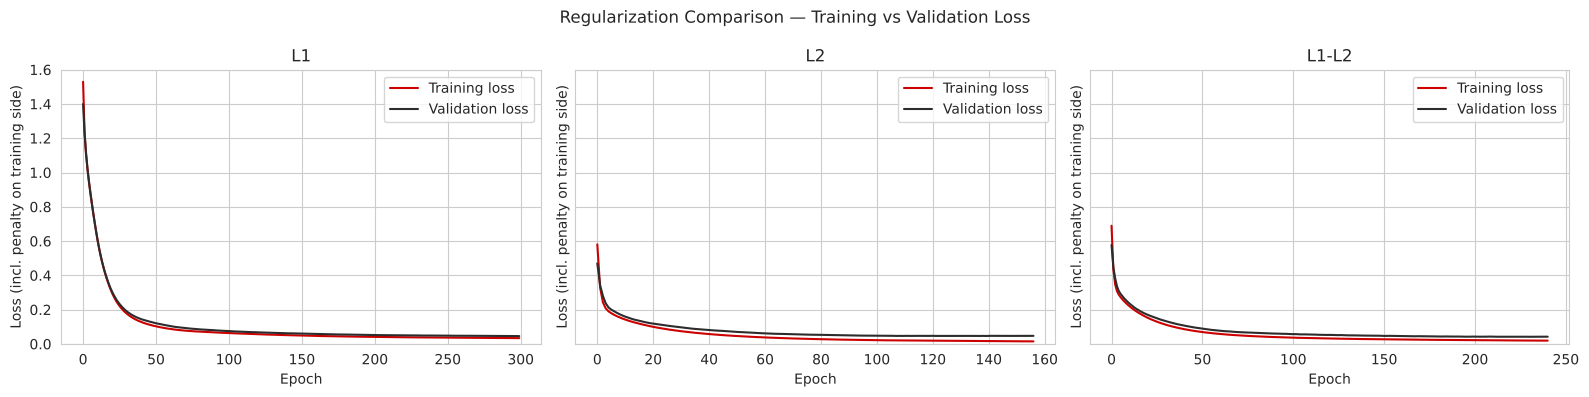

In [40]:
reg_names = ["L1", "L2", "L1-L2"]
reg_hist = [history_l1, history_l2, history_l1l2]

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)       # same y-scale for a fair comparison
for ax, name, h in zip(axes, reg_names, reg_hist):
    ax.plot(h.history["loss"], color=RED, label="Training loss")
    ax.plot(h.history["val_loss"], color=CHARCOAL, label="Validation loss")
    ax.set(title=name, xlabel="Epoch", ylabel="Loss (incl. penalty on training side)", ylim=(0, 1.6))
    ax.legend()
fig.suptitle("Regularization Comparison — Training vs Validation Loss")
plt.tight_layout()
plt.savefig("plots/11_regularization_comparison.png", dpi=120)
plt.show()

In [41]:
rows = []
for name, h in zip(reg_names, reg_hist):
    i = int(np.argmin(h.history["val_loss"]))
    rows.append({"Regularizer": name, "Epochs Trained": len(h.history["loss"]),
                 "Train Loss": h.history["loss"][i], "Val Loss": h.history["val_loss"][i],
                 "Loss Gap": h.history["val_loss"][i] - h.history["loss"][i],
                 "Val Accuracy": h.history["val_accuracy"][i]})
reg_table = pd.DataFrame(rows).set_index("Regularizer").round(4)
reg_table

,Epochs Trained,Train Loss,Val Loss,Loss Gap,Val Accuracy
Regularizer,,,,,
L1,300,0.0340,0.0457,0.0118,1.0000
L2,157,0.0166,0.0464,0.0298,0.9783
L1-L2,241,0.0205,0.0417,0.0212,0.9783


**Observation: regularization comparison**


The smallest train–validation loss gap is for L1 (0.0118), then L1-L2 (0.0212), then L2 (0.0298). L1 also has the best validation accuracy (1.00 vs 0.978 for the other two), while L1-L2 has the lowest validation loss (0.0417).

I would not over-read this. The training loss for L1 is higher (0.034), partly because the penalty itself is included in it, which makes the gap look smaller without the model necessarily generalising better, and the L1 model needed all 300 epochs (its best epoch was the last one, so it could still be improving). The three validation losses are within 0.042–0.046 of each other, so none is clearly best. Theory (L1 = sparsity, L2 = smooth shrinkage, L1-L2 = balance) is consistent with the sparsity check above but not strongly with these accuracy numbers.

### 6.6 - Evaluate all three regularized models

E0000 00:00:1793265571.913020   27253 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


MLP + L1 — test accuracy: 95.61 %  (test loss 0.1545)

               precision    recall  f1-score   support

Malignant (0)       0.91      0.98      0.94        42
   Benign (1)       0.99      0.94      0.96        72

     accuracy                           0.96       114
    macro avg       0.95      0.96      0.95       114
 weighted avg       0.96      0.96      0.96       114



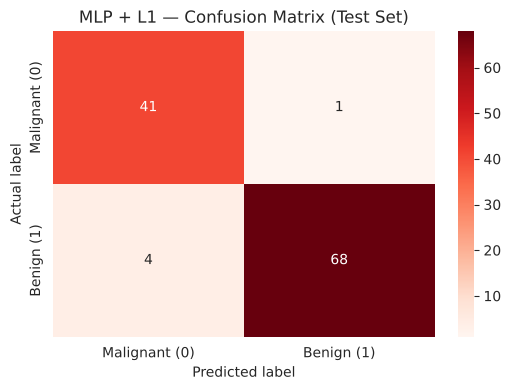

MLP + L2 — test accuracy: 95.61 %  (test loss 0.1282)

               precision    recall  f1-score   support

Malignant (0)       0.91      0.98      0.94        42
   Benign (1)       0.99      0.94      0.96        72

     accuracy                           0.96       114
    macro avg       0.95      0.96      0.95       114
 weighted avg       0.96      0.96      0.96       114



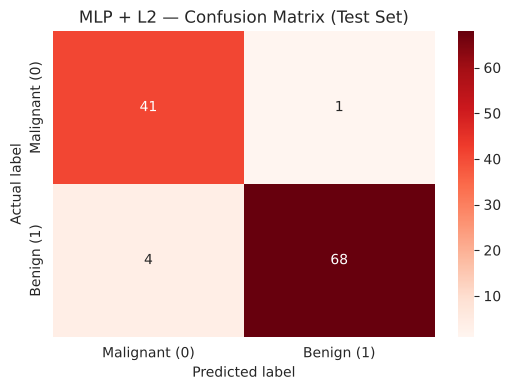

MLP + L1-L2 — test accuracy: 94.74 %  (test loss 0.1442)

               precision    recall  f1-score   support

Malignant (0)       0.89      0.98      0.93        42
   Benign (1)       0.99      0.93      0.96        72

     accuracy                           0.95       114
    macro avg       0.94      0.95      0.94       114
 weighted avg       0.95      0.95      0.95       114



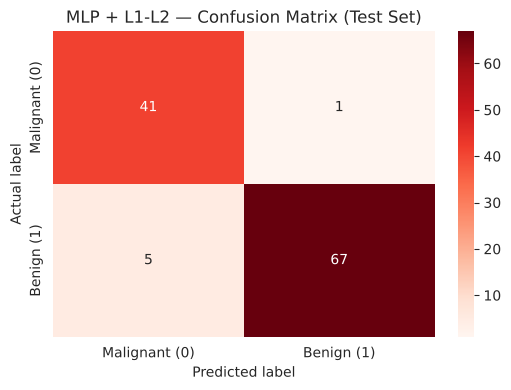

               Model  Test Accuracy (%)
                 SLP              94.74
          MLP (ReLU)              96.49
MLP + Early Stopping              96.49
 MLP + Dropout (0.5)              95.61
            MLP + L1              95.61
            MLP + L2              95.61
         MLP + L1-L2              94.74


In [42]:
reg_models = {"L1": model_l1, "L2": model_l2, "L1-L2": model_l1l2}
reg_acc = {}
for name, m in reg_models.items():
    reg_acc[name], _ = evaluate_on_test(m, f"MLP + {name}", f"plots/12_{name.lower().replace('-', '')}_confusion_matrix.png")
    results.loc[len(results)] = [f"MLP + {name}", round(reg_acc[name] * 100, 2)]
print(results.to_string(index=False))

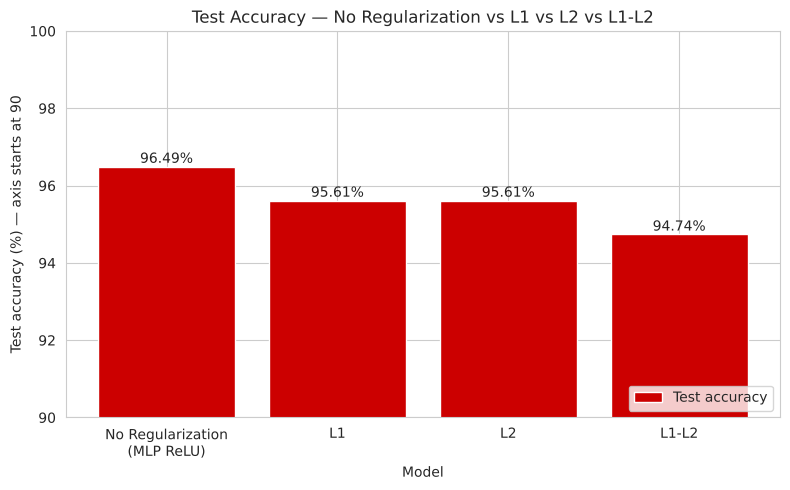

In [43]:
bar_names = [f"No Regularization\n(MLP {best_act})", "L1", "L2", "L1-L2"]
bar_vals = [mlp_acc * 100, reg_acc["L1"] * 100, reg_acc["L2"] * 100, reg_acc["L1-L2"] * 100]

plt.figure(figsize=(8, 5))
bars = plt.bar(bar_names, bar_vals, color=RED)
for b in bars:
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.1, f"{b.get_height():.2f}%", ha="center")
plt.ylim(90, 100)
plt.title("Test Accuracy — No Regularization vs L1 vs L2 vs L1-L2")
plt.xlabel("Model"); plt.ylabel("Test accuracy (%) — axis starts at 90")
plt.legend([bars], ["Test accuracy"], loc="lower right")
plt.tight_layout()
plt.savefig("plots/13_regularization_accuracy_bar.png", dpi=120)
plt.show()

**Observation: test accuracy of the regularized models**


Test accuracy: no regularization 96.49 %, L1 95.61 %, L2 95.61 %, L1-L2 94.74 %. These differ by 1–2 test samples out of 114 (about 0.9 % each), so regularization did **not** improve test accuracy in this run. The dataset is small and fairly easy and the MLP with Early Stopping already generalises well, so there is little overfitting left for a penalty to remove.

## Task 7: Final Comparison, Business Insights & Notebook Quality
**Objective:** combine Dropout, L2 and Early Stopping in one final model and compare every model.

**Expected output:** the final model, a full results table and a clinical insight report.

### 7.1 - Best model: Dropout + L2 + Early Stopping

In [44]:
reset_seed()
final_model = keras.Sequential([
    keras.Input(shape=(30,)),
    keras.layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(0.001)),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l2(0.001)),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(1, activation="sigmoid")
])
final_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
es_final = EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True, verbose=1)
history_final = final_model.fit(X_train_sc, y_train, epochs=300, batch_size=32,
                                validation_split=0.1, callbacks=[es_final], verbose=0)
print("Final model trained for", len(history_final.history["loss"]), "epochs")

Epoch 153: early stopping


Restoring model weights from the end of the best epoch: 133.


Final model trained for 153 epochs


E0000 00:00:1793265589.832772   27253 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Final Combined Model — test accuracy: 95.61 %  (test loss 0.1328)

               precision    recall  f1-score   support

Malignant (0)       0.91      0.98      0.94        42
   Benign (1)       0.99      0.94      0.96        72

     accuracy                           0.96       114
    macro avg       0.95      0.96      0.95       114
 weighted avg       0.96      0.96      0.96       114



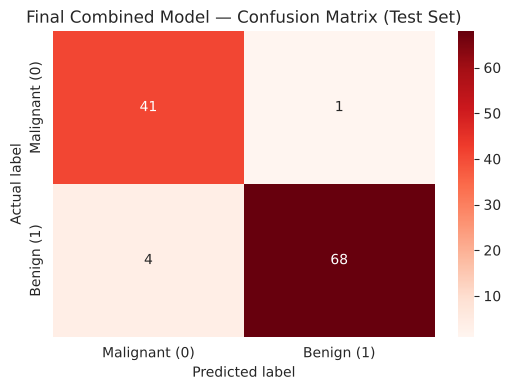

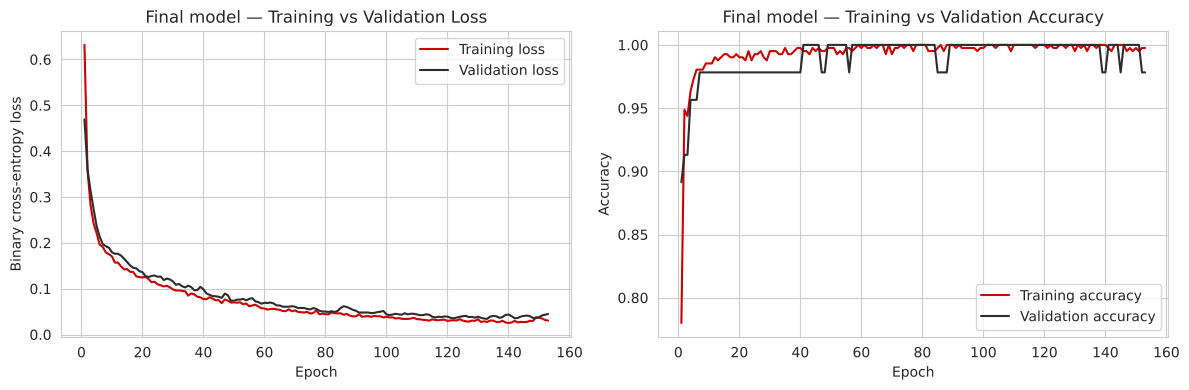

In [45]:
final_acc, y_pred_final = evaluate_on_test(final_model, "Final Combined Model", "plots/14_final_confusion_matrix.png")
plot_loss_acc(history_final, "Final model", "plots/15_final_training_curves.png")

### 7.2 - Full results comparison table

In [46]:
# (name, model, architecture, regularization, dropout rate, early stopping)
all_models = [
    ("SLP (Task 2)",                  model_slp,   "30-1",         "None",       0.0,       "No"),
    (f"MLP-{best_act} (Task 3)",      best_mlp,    "30-64-32-1",   "None",       0.0,       "No"),
    ("MLP + Early Stopping (Task 4)", model_es,    "30-128-64-1",  "None",       0.0,       "Yes (patience=15)"),
    ("MLP + Dropout-best (Task 5)",   best_drop,   "30-128-64-1",  "None",       best_rate, "Yes (patience=20)"),
    ("MLP + L2 (Task 6)",             model_l2,    "30-128-64-1",  "L2 (0.001)", 0.0,       "Yes (patience=20)"),
    ("Final Combined (Task 7.1)",     final_model, "30-128-64-1",  "L2 (0.001)", 0.3,       "Yes (patience=20)"),
]
rows = []
for name, m, arch, reg, rate, stop in all_models:
    yp = (m.predict(X_test_sc, verbose=0) > 0.5).astype(int).ravel()
    rows.append({"Model": name, "Architecture": arch, "Regularization": reg, "Dropout Rate": rate,
                 "Early Stopping": stop,
                 "Test Accuracy": accuracy_score(y_test, yp),
                 "Test Precision": precision_score(y_test, yp, pos_label=0),   # Malignant class
                 "Test Recall": recall_score(y_test, yp, pos_label=0),
                 "Test F1-Score": f1_score(y_test, yp, pos_label=0)})
final_results = pd.DataFrame(rows)
metric_cols = ["Test Accuracy", "Test Precision", "Test Recall", "Test F1-Score"]
final_results.style.format("{:.4f}", subset=metric_cols)\
    .highlight_max(subset=["Test Accuracy", "Test F1-Score"], color="#ffcccc")

,Model,Architecture,Regularization,Dropout Rate,Early Stopping,Test Accuracy,Test Precision,Test Recall,Test F1-Score
0,SLP (Task 2),30-1,None,0.000000,No,0.9474,0.9500,0.9048,0.9268
1,MLP-ReLU (Task 3),30-64-32-1,None,0.000000,No,0.9649,0.9318,0.9762,0.9535
2,MLP + Early Stopping (Task 4),30-128-64-1,None,0.000000,Yes (patience=15),0.9649,0.9318,0.9762,0.9535
3,MLP + Dropout-best (Task 5),30-128-64-1,None,0.500000,Yes (patience=20),0.9561,0.9111,0.9762,0.9425
4,MLP + L2 (Task 6),30-128-64-1,L2 (0.001),0.000000,Yes (patience=20),0.9561,0.9111,0.9762,0.9425
5,Final Combined (Task 7.1),30-128-64-1,L2 (0.001),0.300000,Yes (patience=20),0.9561,0.9111,0.9762,0.9425


In [47]:
final_results.to_csv("results_table.csv", index=False)
print(final_results.drop(columns=["Architecture"]).round(4).to_markdown(index=False))

| Model                         | Regularization   |   Dropout Rate | Early Stopping    |   Test Accuracy |   Test Precision |   Test Recall |   Test F1-Score |
|:------------------------------|:-----------------|---------------:|:------------------|----------------:|-----------------:|--------------:|----------------:|
| SLP (Task 2)                  | None             |            0   | No                |          0.9474 |           0.95   |        0.9048 |          0.9268 |
| MLP-ReLU (Task 3)             | None             |            0   | No                |          0.9649 |           0.9318 |        0.9762 |          0.9535 |
| MLP + Early Stopping (Task 4) | None             |            0   | Yes (patience=15) |          0.9649 |           0.9318 |        0.9762 |          0.9535 |
| MLP + Dropout-best (Task 5)   | None             |            0.5 | Yes (patience=20) |          0.9561 |           0.9111 |        0.9762 |          0.9425 |
| MLP + L2 (Task 6)             | 

### 7.3 - Business insight report

In [48]:
# the model outputs P(Benign). A HIGHER benign-threshold makes it harder to call a tumour Benign.
y_prob = final_model.predict(X_test_sc, verbose=0).ravel()
rows = []
for t in [0.3, 0.5, 0.7, 0.8, 0.9, 0.95]:
    yp = (y_prob > t).astype(int)
    rows.append({"Benign threshold": t,
                 "Missed malignant (FN)": int(((y_test.values == 0) & (yp == 1)).sum()),
                 "Benign flagged malignant (FP)": int(((y_test.values == 1) & (yp == 0)).sum())})
pd.DataFrame(rows).set_index("Benign threshold")

,Missed malignant (FN),Benign flagged malignant (FP)
Benign threshold,,
0.30,1,3
0.50,1,4
0.70,1,4
0.80,1,4
0.90,1,6
0.95,1,7


## Clinical Insight for Medical Diagnosis Support


**Results first.** All MLP variants have the same Malignant recall of 0.976 (1 missed malignant tumour out of 42), while the SLP missed 4 (recall 0.905). The best accuracy / F1 are 0.9649 / 0.9535 (MLP-ReLU and MLP + Early Stopping); the Dropout-best, L2 and final combined models score 0.9561 / 0.9425. These gaps are 1 test sample, well within the noise of a 114-sample test set.

**(a) Which model would I deploy?** The final combined model (Dropout 0.3 + L2 + Early Stopping), not the SLP. The clear gain in this whole project is SLP → MLP (4 missed cancers down to 1). Among the MLPs the test scores are practically tied, so I prefer the one with all three safeguards because it should be the most stable on new patients, even though it did not win on this particular test set. In cancer diagnosis a false negative (missed malignant case) is far more costly than a false positive (an extra check), so Malignant **recall** matters more than accuracy. The final model has recall 0.98 with precision 0.91 (4 benign cases flagged), which I consider an acceptable trade-off. A real tool would still need cross-validation on more data and a doctor making the final call.

**(b) Which threshold?** The model outputs P(Benign). The default 0.5 means "call it Benign if the probability is above 0.5", so being more careful about malignant cases means a **higher** benign threshold (equivalently, flagging a tumour when its malignant probability exceeds about 0.2–0.3). In my threshold test the missed-malignant count stayed at 1 from 0.3 up to 0.95, while false alarms were 3 at 0.3, 4 from 0.5 to 0.8, then 6 at 0.9 and 7 at 0.95. So the one missed tumour is a confidently wrong prediction that no threshold fixes, and raising the threshold above 0.8 only adds false alarms. On this test set a threshold of 0.7–0.8 costs nothing compared with 0.5, so I would use it as a safety margin, and send borderline cases to a doctor. (Choosing the threshold on the test set is optimistic; it should really be tuned on validation data.)

**(c) Which technique helped generalisation most?** Early Stopping had the clearest measurable effect: the validation loss without it rose from 0.0301 to 0.0449 by epoch 300, while with it training stopped at the best point after 64 epochs. Dropout and L1/L2 did not improve test accuracy (all about 95–96 %), and the biggest improvement overall came from adding hidden layers, not from regularization. The dataset is small and clean, so the benefit of regularization may simply be small here.